In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:

import os

# Crear carpeta para guardar los datos
os.makedirs("data", exist_ok=True)

# Descargar archivo de entrenamiento
!wget -O data/KDDTrain+.txt "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"

# Descargar archivo de prueba
!wget -O data/KDDTest+.txt "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"

# Comprobar que se han descargado
print("Archivos descargados:")
print(os.listdir("data"))

--2026-11-20 11:46:15--  https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 19109424 (18M) [text/plain]
Saving to: ‘data/KDDTrain+.txt’

data/KDDTrain+.txt  100%[===================>]  18.22M  --.-KB/s    in 0.1s    

2026-11-20 11:46:15 (162 MB/s) - ‘data/KDDTrain+.txt’ saved [19109424/19109424]

--2026-11-20 11:46:15--  https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 344151

In [3]:

import pandas as pd
import os

# Nombres de las 41 características del tráfico
columnas = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

# Cargar los datos de entrenamiento
df = pd.read_csv(
    "data/KDDTrain+.txt",
    header=None,
    names=columnas
)

# Crear columna que identifica los ataques
df["is_attack"] = (df["label"] != "normal").astype(int)

# Mostrar información
print("Tamaño de los datos:", df.shape)
print("\nPrimeras 5 conexiones:")
display(df.head())

Tamaño de los datos: (125973, 44)

Primeras 5 conexiones:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,0
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,0
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,1
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,0
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,0


In [4]:

# Contar conexiones normales y ataques
print("DISTRIBUCIÓN DEL TRÁFICO")

conteo = df["is_attack"].value_counts()

print("Conexiones normales:", conteo.get(0, 0))
print("Conexiones de ataque:", conteo.get(1, 0))

# Calcular porcentajes
print("\nPORCENTAJES")

print((df["is_attack"].value_counts(normalize=True) * 100).round(2))

# Mostrar los 10 ataques más frecuentes
print("\nATAQUES MÁS FRECUENTES")

ataques = df[df["is_attack"] == 1]["label"].value_counts()

display(ataques.head(10))

DISTRIBUCIÓN DEL TRÁFICO
Conexiones normales: 67343
Conexiones de ataque: 58630

PORCENTAJES
is_attack
0    53.46
1    46.54
Name: proportion, dtype: float64

ATAQUES MÁS FRECUENTES


,count
label,
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892
warezclient,890


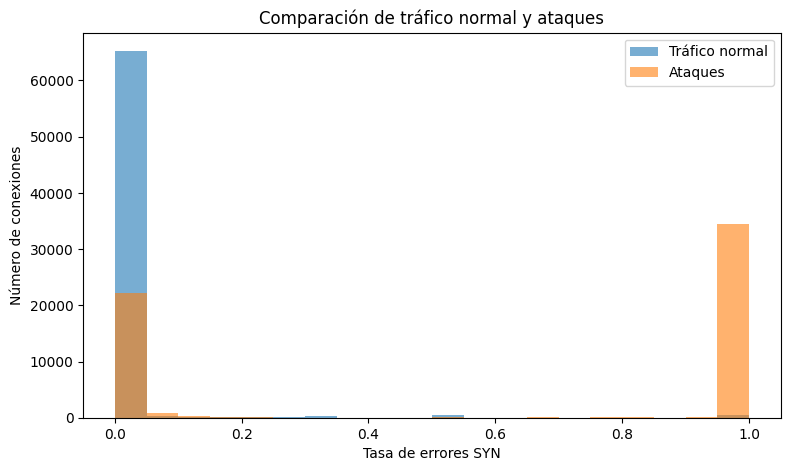

In [5]:

import matplotlib.pyplot as plt

# Comparar errores SYN entre tráfico normal y ataques
plt.figure(figsize=(9,5))

plt.hist(
    df[df["is_attack"] == 0]["serror_rate"],
    bins=20,
    alpha=0.6,
    label="Tráfico normal"
)

plt.hist(
    df[df["is_attack"] == 1]["serror_rate"],
    bins=20,
    alpha=0.6,
    label="Ataques"
)

plt.xlabel("Tasa de errores SYN")
plt.ylabel("Número de conexiones")
plt.title("Comparación de tráfico normal y ataques")
plt.legend()
plt.show()

In [6]:
# Regla manual: si serror_rate > 0.5, sospechamos que es un ataque
df["prediccion_regla"] = (df["serror_rate"] > 0.5).astype(int)

# Comparar predicción con la etiqueta real
from sklearn.metrics import confusion_matrix, classification_report

print("Matriz de confusión:")
print(confusion_matrix(df["is_attack"], df["prediccion_regla"]))

print("\nInforme de resultados:")
print(classification_report(df["is_attack"], df["prediccion_regla"]))

Matriz de confusión:
[[66906   437]
 [23800 34830]]

Informe de resultados:
              precision    recall  f1-score   support

           0       0.74      0.99      0.85     67343
           1       0.99      0.59      0.74     58630

    accuracy                           0.81    125973
   macro avg       0.86      0.79      0.79    125973
weighted avg       0.85      0.81      0.80    125973



In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Seleccionar las tres características
X = df[["serror_rate", "same_srv_rate", "count"]]
y = df["is_attack"]

# Crear y entrenar el árbol
arbol = DecisionTreeClassifier(max_depth=1, random_state=42)
arbol.fit(X, y)

# Realizar predicciones
predicciones = arbol.predict(X)

# Evaluar resultados
print("Matriz de confusión:")
print(confusion_matrix(y, predicciones))

print("\nInforme de resultados:")
print(classification_report(y, predicciones))

Matriz de confusión:
[[65563  1780]
 [14890 43740]]

Informe de resultados:
              precision    recall  f1-score   support

           0       0.81      0.97      0.89     67343
           1       0.96      0.75      0.84     58630

    accuracy                           0.87    125973
   macro avg       0.89      0.86      0.86    125973
weighted avg       0.88      0.87      0.87    125973



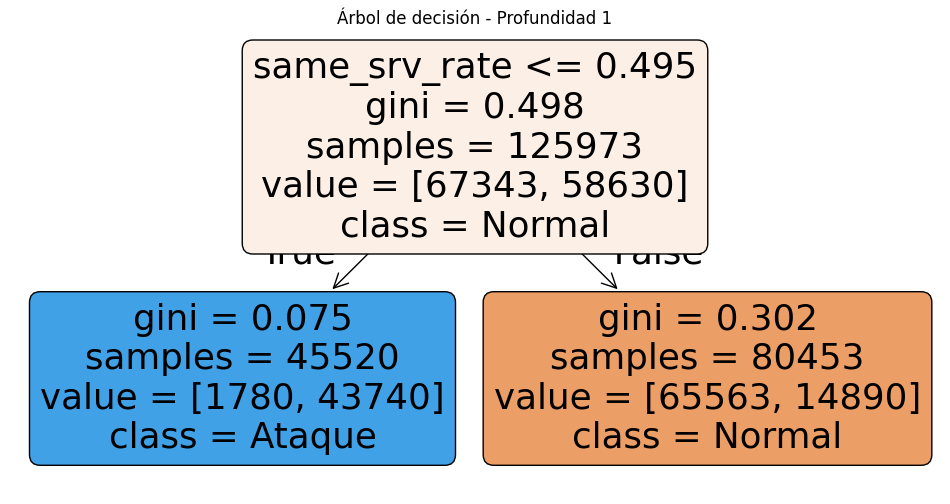

In [8]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plot_tree(
    arbol,
    feature_names=["serror_rate", "same_srv_rate", "count"],
    class_names=["Normal", "Ataque"],
    filled=True,
    rounded=True
)

plt.title("Árbol de decisión - Profundidad 1")
plt.show()

In [9]:
# Cargar el conjunto de prueba
df_test = pd.read_csv(
    "data/KDDTest+.txt",
    header=None,
    names=columnas
)

# Crear la etiqueta de ataque
df_test["is_attack"] = (df_test["label"] != "normal").astype(int)

# Seleccionar las mismas características
X_test = df_test[["serror_rate", "same_srv_rate", "count"]]
y_test = df_test["is_attack"]

# Evaluar el árbol con datos nuevos
pred_test = arbol.predict(X_test)

print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_test))

print("\nInforme de resultados:")
print(classification_report(y_test, pred_test))

Matriz de confusión:
[[9566  145]
 [6966 5867]]

Informe de resultados:
              precision    recall  f1-score   support

           0       0.58      0.99      0.73      9711
           1       0.98      0.46      0.62     12833

    accuracy                           0.68     22544
   macro avg       0.78      0.72      0.68     22544
weighted avg       0.80      0.68      0.67     22544



In [10]:
profundidades = [1, 2, 3, 5, 8, 12, 20, None]

resultados = []

for profundidad in profundidades:

    modelo = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=42
    )

    modelo.fit(X, y)

    pred_train = modelo.predict(X)
    pred_test = modelo.predict(X_test)

    resultados.append({
        "Profundidad": profundidad,
        "Accuracy entrenamiento": modelo.score(X, y),
        "Accuracy prueba": modelo.score(X_test, y)
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(3))

ValueError: Found input variables with inconsistent numbers of samples: [125973, 22544]

In [11]:
profundidades = [1, 2, 3, 5, 8, 12, 20, None]

resultados = []

for profundidad in profundidades:

    modelo = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=42
    )

    modelo.fit(X, y)

    resultados.append({
        "Profundidad": profundidad,
        "Accuracy entrenamiento": modelo.score(X, y),
        "Accuracy prueba": modelo.score(X_test, y_test)
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(3))

,Profundidad,Accuracy entrenamiento,Accuracy prueba
0,1.0,0.868,0.685
1,2.0,0.887,0.665
2,3.0,0.896,0.699
3,5.0,0.898,0.678
4,8.0,0.901,0.676
5,12.0,0.902,0.677
6,20.0,0.902,0.676
7,NaN,0.902,0.676


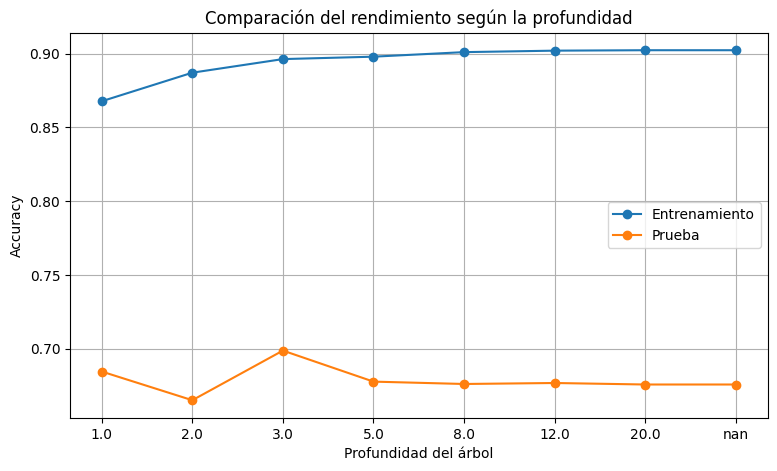

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    tabla_resultados["Profundidad"].astype(str),
    tabla_resultados["Accuracy entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    tabla_resultados["Profundidad"].astype(str),
    tabla_resultados["Accuracy prueba"],
    marker="o",
    label="Prueba"
)

plt.xlabel("Profundidad del árbol")
plt.ylabel("Accuracy")
plt.title("Comparación del rendimiento según la profundidad")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
total_eventos = 1_000_000
tasa_ataques = 0.0001
tpr = 0.99
fpr = 0.01

ataques_reales = total_eventos * tasa_ataques
eventos_normales = total_eventos - ataques_reales

verdaderos_positivos = ataques_reales * tpr
falsos_negativos = ataques_reales * (1 - tpr)

falsos_positivos = eventos_normales * fpr
verdaderos_negativos = eventos_normales * (1 - fpr)

precision = verdaderos_positivos / (
    verdaderos_positivos + falsos_positivos
)

print("Ataques reales:", int(ataques_reales))
print("Ataques detectados:", int(verdaderos_positivos))
print("Falsas alarmas:", int(falsos_positivos))
print("Precisión:", round(precision * 100, 2), "%")

Ataques reales: 100
Ataques detectados: 99
Falsas alarmas: 9999
Precisión: 0.98 %


In [14]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Crear datos sintéticos
cps = np.random.normal(50, 15, 1000)

# Crear etiqueta: 1 = anomalía, 0 = normal
is_attack = (cps > 90).astype(int)

df_sintetico = pd.DataFrame({
    "cps": cps,
    "is_attack": is_attack
})

display(df_sintetico.head())

print("\nDistribución:")
print(df_sintetico["is_attack"].value_counts())

,cps,is_attack
0,57.450712,0
1,47.926035,0
2,59.715328,0
3,72.845448,0
4,46.487699,0



Distribución:
is_attack
0    997
1      3
Name: count, dtype: int64


In [15]:
import numpy as np

# Cuatro flujos sintéticos del laboratorio
cps = np.array([2, 3, 40, 55])

# Etiquetas reales: 0 = normal, 1 = ataque
etiquetas = np.array([0, 0, 1, 1])

print("Conexiones por segundo:", cps)
print("Etiquetas reales:", etiquetas)

Conexiones por segundo: [ 2  3 40 55]
Etiquetas reales: [0 0 1 1]


In [16]:
# Crear umbrales candidatos
candidatos = np.r_[
    cps.min() - 1,
    (cps[:-1] + cps[1:]) / 2,
    cps.max() + 1
]

# Probar cada umbral
for t in candidatos:
    prediccion = (cps > t).astype(int)
    errores = (prediccion != etiquetas).sum()

    print("Umbral:", t, "| Errores:", errores)

Umbral: 1.0 | Errores: 2
Umbral: 2.5 | Errores: 1
Umbral: 21.5 | Errores: 0
Umbral: 47.5 | Errores: 1
Umbral: 56.0 | Errores: 2


In [17]:
# Añadir el quinto flujo
cps = np.array([2, 3, 25, 40, 55])
etiquetas = np.array([0, 0, 1, 1, 1])

# Ordenar y generar nuevos umbrales candidatos
orden = np.argsort(cps)
cps = cps[orden]
etiquetas = etiquetas[orden]

candidatos = np.r_[
    cps.min() - 1,
    (cps[:-1] + cps[1:]) / 2,
    cps.max() + 1
]

# Evaluar cada umbral con coste ponderado
for t in candidatos:
    prediccion = (cps > t).astype(int)

    fp = ((etiquetas == 0) & (prediccion == 1)).sum()
    fn = ((etiquetas == 1) & (prediccion == 0)).sum()

    coste = fp + 5 * fn

    print("Umbral:", t, "| FP:", fp, "| FN:", fn, "| Coste:", coste)

Umbral: 1.0 | FP: 2 | FN: 0 | Coste: 2
Umbral: 2.5 | FP: 1 | FN: 0 | Coste: 1
Umbral: 14.0 | FP: 0 | FN: 0 | Coste: 0
Umbral: 32.5 | FP: 0 | FN: 1 | Coste: 5
Umbral: 47.5 | FP: 0 | FN: 2 | Coste: 10
Umbral: 56.0 | FP: 0 | FN: 3 | Coste: 15


In [18]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)

n = 5000

# Etiquetas: 1 = phishing, 0 = normal
y_email = rng.binomial(1, 0.30, n)

# Crear características sintéticas
urgente = np.where(
    y_email == 1,
    rng.binomial(1, 0.60, n),
    rng.binomial(1, 0.10, n)
)

dominio_distinto = np.where(
    y_email == 1,
    rng.binomial(1, 0.70, n),
    rng.binomial(1, 0.05, n)
)

adjunto_exe = np.where(
    y_email == 1,
    rng.binomial(1, 0.25, n),
    rng.binomial(1, 0.01, n)
)

df_email = pd.DataFrame({
    "urgente": urgente,
    "dominio_distinto": dominio_distinto,
    "adjunto_exe": adjunto_exe,
    "phishing": y_email
})

display(df_email.head())

print("\nDistribución de correos:")
print(df_email["phishing"].value_counts())

,urgente,dominio_distinto,adjunto_exe,phishing
0,0,0,0,0
1,0,1,1,1
2,1,1,0,1
3,0,0,0,0
4,0,0,0,0



Distribución de correos:
phishing
0    3511
1    1489
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

# Variables de entrada
X_email = df_email[
    ["urgente", "dominio_distinto", "adjunto_exe"]
]

# Etiqueta real
y_email = df_email["phishing"]

# Separar datos: 70 % entrenamiento y 30 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_email,
    y_email,
    test_size=0.3,
    stratify=y_email,
    random_state=7
)

print("Correos de entrenamiento:", len(X_train))
print("Correos de prueba:", len(X_test))

Correos de entrenamiento: 3500
Correos de prueba: 1500


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score

# Regla manual: urgente = 1 significa phishing
pred_regla = X_test["urgente"]

# Crear y entrenar regresión logística
modelo_email = LogisticRegression(random_state=7)
modelo_email.fit(X_train, y_train)

# Predecir sobre los datos de prueba
pred_modelo = modelo_email.predict(X_test)

# Comparar resultados
print("REGLA MANUAL")
print("Precisión:", round(precision_score(y_test, pred_regla), 2))
print("Recall:", round(recall_score(y_test, pred_regla), 2))

print("\nREGRESIÓN LOGÍSTICA")
print("Precisión:", round(precision_score(y_test, pred_modelo), 2))
print("Recall:", round(recall_score(y_test, pred_modelo), 2))

REGLA MANUAL
Precisión: 0.7
Recall: 0.56

REGRESIÓN LOGÍSTICA
Precisión: 0.85
Recall: 0.77


In [21]:
# Mostrar los coeficientes aprendidos
pesos = pd.DataFrame({
    "Señal": X_email.columns,
    "Coeficiente": modelo_email.coef_[0]
})

display(pesos.round(3))

print("Término independiente:", modelo_email.intercept_[0].round(3))

,Señal,Coeficiente
0,urgente,2.432
1,dominio_distinto,3.672
2,adjunto_exe,3.272


Término independiente: -2.985


In [22]:
# Crear una nueva simulación con deriva de datos
rng = np.random.default_rng(7)

n = 5000
y_deriva = rng.binomial(1, 0.30, n)

urgente_deriva = np.where(
    y_deriva == 1,
    rng.binomial(1, 0.60, n),
    rng.binomial(1, 0.10, n)
)

dominio_deriva = np.where(
    y_deriva == 1,
    rng.binomial(1, 0.20, n),  # Antes era 0.70
    rng.binomial(1, 0.05, n)
)

adjunto_deriva = np.where(
    y_deriva == 1,
    rng.binomial(1, 0.25, n),
    rng.binomial(1, 0.01, n)
)

X_deriva = pd.DataFrame({
    "urgente": urgente_deriva,
    "dominio_distinto": dominio_deriva,
    "adjunto_exe": adjunto_deriva
})

# Aplicar el mismo modelo, sin reentrenarlo
pred_deriva = modelo_email.predict(X_deriva)

# Comparar el recall antes y después
recall_antes = recall_score(y_test, pred_modelo)
recall_despues = recall_score(y_deriva, pred_deriva)

print("Recall antes de la deriva:", round(recall_antes, 3))
print("Recall después de la deriva:", round(recall_despues, 3))
print(
    "Caída del recall:",
    round((recall_antes - recall_despues) * 100, 2),
    "puntos porcentuales"
)

Recall antes de la deriva: 0.77
Recall después de la deriva: 0.408
Caída del recall: 36.12 puntos porcentuales
